In [1]:
#Task 7.1

import torch
import torchvision
import torchvision.transforms as transforms

# Let us define transformations for data normalization, convert images to tensors and normalize to [-1, 1]
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

# Let us load CIFAR-10 dataset
trainset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
testset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)

# Then we define DataLoaders to load the data in batches
trainloader = torch.utils.data.DataLoader(trainset, batch_size=64, shuffle=True, num_workers=2)
testloader = torch.utils.data.DataLoader(testset, batch_size=64, shuffle=False, num_workers=2)

# These are the CIFAR-10 class labels
classes = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


100%|██████████| 170M/170M [00:03<00:00, 47.9MB/s]


Extracting ./data/cifar-10-python.tar.gz to ./data
Files already downloaded and verified


In [3]:
#Task 7.2

# 1st let us specify the classes we want to sample
selected_classes = [0, 1, 2, 3, 4]

# Then define the filtering function
def filter_classes(dataset):
    indices = [i for i, (_, label) in enumerate(dataset) if label in selected_classes]
    dataset.targets = [dataset.targets[i] for i in indices]
    dataset.data = dataset.data[indices]
    return dataset

# Now pply the filtering function to both train and test datasets
trainset = filter_classes(trainset)
testset = filter_classes(testset)

# We check unique classes in the dataset
print("Unique classes in train set:", set(trainset.targets))
print("Unique classes in test set:", set(testset.targets))


Unique classes in train set: {0, 1, 2, 3, 4}
Unique classes in test set: {0, 1, 2, 3, 4}


In [4]:
#Task 7.3

import torch
import torch.nn as nn
import torch.optim as optim

# We now define the neural network model
class SimpleNN(nn.Module):
    def __init__(self):
        super(SimpleNN, self).__init__()

        # We flatten the input image (CIFAR-10 images are 32x32x3)
        self.flatten = nn.Flatten()

        # The layers here are : Input -> Hidden1 -> Hidden2 -> Hidden3 -> Output
        # As my id is 210042132 so there are 132 neurons
        self.fc1 = nn.Linear(32 * 32 * 3, 132)  # Input to Hidden1
        self.fc2 = nn.Linear(132, 132)  # Hidden1 to Hidden2
        self.fc3 = nn.Linear(132, 132)  # Hidden2 to Hidden3
        self.fc4 = nn.Linear(132, 10)  # Hidden3 to Output

        # Lastly we define activation function
        self.relu = nn.ReLU()
# We do not need any activation for the output layer
    def forward(self, x):
        x = self.flatten(x)
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.relu(self.fc3(x))
        x = self.fc4(x)
        return x

model = SimpleNN()

# We need to define loss function, optimizer, number of epochs
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
epochs = 10

# Now let us make the training loop
for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    # We iterate through the training data
    for inputs, labels in trainloader:

        # Zero the parameter gradients
        optimizer.zero_grad()

        # We have forward pass, Backward pass and optimization
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        # Calculate the running loss and accuracy
        running_loss += loss.item()
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    # Print statistics after each epoch
    print(f"Epoch {epoch+1}/{epochs}, Loss: {running_loss/len(trainloader):.4f}, Accuracy: {100 * correct/total:.2f}%")

# Test the model on the test dataset
model.eval()  # Set the model to evaluation mode
correct = 0
total = 0
with torch.no_grad():  # No need to compute gradients during evaluation
    for inputs, labels in testloader:
        outputs = model(inputs)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print(f"Test Accuracy: {100 * correct/total:.2f}%")


Epoch 1/10, Loss: 1.1540, Accuracy: 53.98%
Epoch 2/10, Loss: 0.9708, Accuracy: 62.11%
Epoch 3/10, Loss: 0.8971, Accuracy: 65.37%
Epoch 4/10, Loss: 0.8296, Accuracy: 68.44%
Epoch 5/10, Loss: 0.7734, Accuracy: 70.12%
Epoch 6/10, Loss: 0.7172, Accuracy: 72.72%
Epoch 7/10, Loss: 0.6724, Accuracy: 74.36%
Epoch 8/10, Loss: 0.6252, Accuracy: 75.80%
Epoch 9/10, Loss: 0.5774, Accuracy: 77.98%
Epoch 10/10, Loss: 0.5336, Accuracy: 79.61%
Test Accuracy: 66.00%


Epoch 1/10, Loss: 1.1594, Accuracy: 55.12%
Epoch 2/10, Loss: 0.9985, Accuracy: 61.29%
Epoch 3/10, Loss: 0.9297, Accuracy: 64.36%
Epoch 4/10, Loss: 0.8857, Accuracy: 65.69%
Epoch 5/10, Loss: 0.8546, Accuracy: 67.66%
Epoch 6/10, Loss: 0.8225, Accuracy: 68.41%
Epoch 7/10, Loss: 0.8044, Accuracy: 69.43%
Epoch 8/10, Loss: 0.7761, Accuracy: 70.53%
Epoch 9/10, Loss: 0.7571, Accuracy: 71.00%
Epoch 10/10, Loss: 0.7315, Accuracy: 72.27%
Test Accuracy: 64.34%
Epoch 1/10, Loss: 1.9295, Accuracy: 20.44%
Epoch 2/10, Loss: 1.5330, Accuracy: 32.10%
Epoch 3/10, Loss: 1.4719, Accuracy: 33.56%
Epoch 4/10, Loss: 1.4416, Accuracy: 34.57%
Epoch 5/10, Loss: 1.4239, Accuracy: 34.38%
Epoch 6/10, Loss: 1.4107, Accuracy: 34.02%
Epoch 7/10, Loss: 1.3987, Accuracy: 33.22%
Epoch 8/10, Loss: 1.3878, Accuracy: 34.83%
Epoch 9/10, Loss: 1.3782, Accuracy: 36.55%
Epoch 10/10, Loss: 1.3693, Accuracy: 37.64%
Test Accuracy: 37.30%


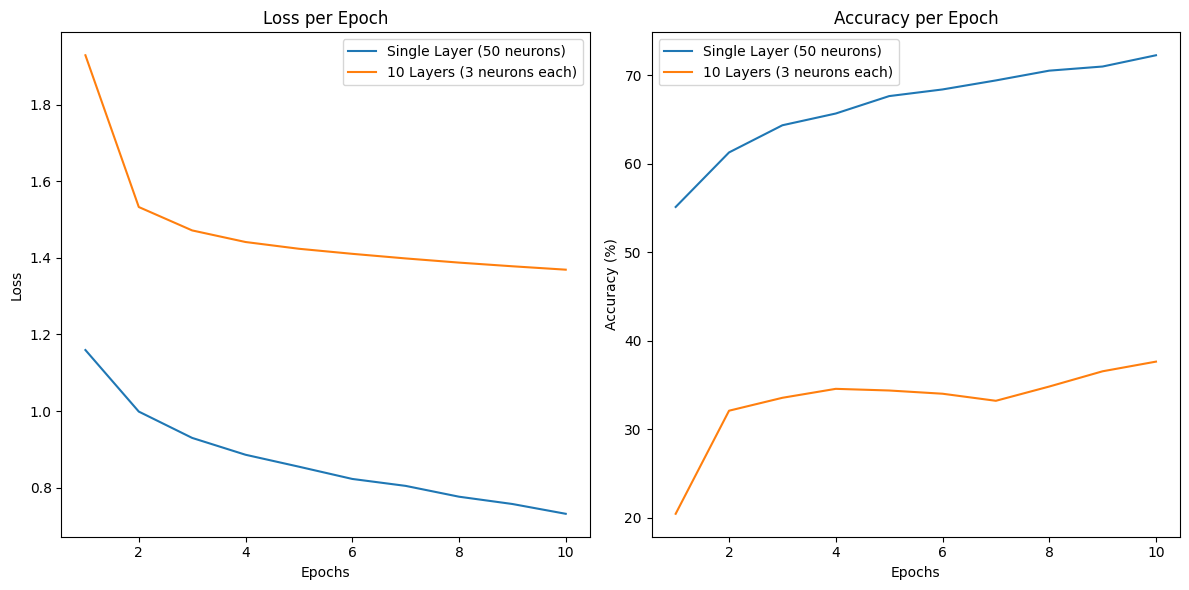

In [5]:
#Task 7.4

import matplotlib.pyplot as plt

# 1st we define a model with a single layer of 50 neurons
class SingleLayerNN(nn.Module):
    def __init__(self):
        super(SingleLayerNN, self).__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(32 * 32 * 3, 50)  # Input to a single hidden layer with 50 neurons
        self.fc2 = nn.Linear(50, 10)  # Hidden layer to output

        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.flatten(x)
        x = self.relu(self.fc1(x))
        x = self.fc2(x)  # No activation for the output layer
        return x

# Then wefine a model with 10 layers, each having 3 neurons
class TenLayerNN(nn.Module):
    def __init__(self):
        super(TenLayerNN, self).__init__()
        self.flatten = nn.Flatten()

        # Create 10 hidden layers with 3 neurons each
        self.fc_layers = nn.ModuleList([nn.Linear(32 * 32 * 3 if i == 0 else 3, 3) for i in range(10)])
        self.fc_out = nn.Linear(3, 10)  # Output layer to 10 classes

        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.flatten(x)
        for fc in self.fc_layers:
            x = self.relu(fc(x))  # Apply ReLU after each hidden layer
        x = self.fc_out(x)  # No activation for the output layer
        return x

# Function to train and evaluate models
def train_and_evaluate(model, trainloader, testloader, epochs=10, lr=0.001):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    # Track loss and accuracy
    epoch_losses = []
    epoch_accuracies = []

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0

        # Training loop
        for inputs, labels in trainloader:
            optimizer.zero_grad()  # Zero the gradients

            # Forward pass
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            # Backward pass and optimization
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        # Calculate loss and accuracy for the epoch
        epoch_losses.append(running_loss / len(trainloader))
        epoch_accuracies.append(100 * correct / total)
        print(f"Epoch {epoch+1}/{epochs}, Loss: {running_loss/len(trainloader):.4f}, Accuracy: {100 * correct/total:.2f}%")

    # Test the model after training
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for inputs, labels in testloader:
            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    print(f"Test Accuracy: {100 * correct/total:.2f}%")

    return epoch_losses, epoch_accuracies

# 3. Train the model with a single hidden layer with 50 neurons
single_layer_model = SingleLayerNN()
losses_single, accuracies_single = train_and_evaluate(single_layer_model, trainloader, testloader)

# 4. Train the model with 10 hidden layers, each having 3 neurons
ten_layer_model = TenLayerNN()
losses_ten, accuracies_ten = train_and_evaluate(ten_layer_model, trainloader, testloader)

# Plotting the Loss and Accuracy
epochs = range(1, 11)  # Epoch range (1 to 10)

# Plot Loss
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.plot(epochs, losses_single, label='Single Layer (50 neurons)')
plt.plot(epochs, losses_ten, label='10 Layers (3 neurons each)')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Loss per Epoch')
plt.legend()

# Plot Accuracy
plt.subplot(1, 2, 2)
plt.plot(epochs, accuracies_single, label='Single Layer (50 neurons)')
plt.plot(epochs, accuracies_ten, label='10 Layers (3 neurons each)')
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.title('Accuracy per Epoch')
plt.legend()

plt.tight_layout()
plt.show()


Epoch 1/10, Loss: 1.3856, Accuracy: 43.65%
Epoch 2/10, Loss: 1.2159, Accuracy: 51.57%
Epoch 3/10, Loss: 1.1779, Accuracy: 53.42%
Epoch 4/10, Loss: 1.1333, Accuracy: 55.17%
Epoch 5/10, Loss: 1.1149, Accuracy: 55.88%
Epoch 6/10, Loss: 1.0982, Accuracy: 56.93%
Epoch 7/10, Loss: 1.0803, Accuracy: 57.69%
Epoch 8/10, Loss: 1.0704, Accuracy: 57.95%
Epoch 9/10, Loss: 1.0608, Accuracy: 58.82%
Epoch 10/10, Loss: 1.0503, Accuracy: 59.02%
Test Accuracy with Dropout: 62.82%


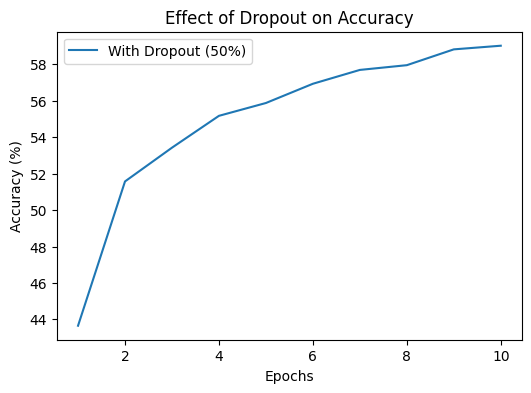

In [15]:
#Task 7.5

import torch.nn as nn
import torch.optim as optim
import torch
import matplotlib.pyplot as plt

# Define the modified neural network model with Dropout
class SimpleNNWithDropout(nn.Module):
    def __init__(self):
        super(SimpleNNWithDropout, self).__init__()

        self.flatten = nn.Flatten()

        # Define layers with dropout after each hidden layer
        self.fc1 = nn.Linear(32 * 32 * 3, 132)  # Input to Hidden1
        self.dropout1 = nn.Dropout(p=0.5)  # 50% dropout after first hidden layer

        self.fc2 = nn.Linear(132, 132)  # Hidden1 to Hidden2
        self.dropout2 = nn.Dropout(p=0.5)  # 50% dropout after second hidden layer

        self.fc3 = nn.Linear(132, 132)  # Hidden2 to Hidden3
        self.dropout3 = nn.Dropout(p=0.5)  # 50% dropout after third hidden layer

        self.fc4 = nn.Linear(132, 10)  # Hidden3 to Output

        self.relu = nn.ReLU()  # ReLU activation function

    def forward(self, x):
        x = self.flatten(x)
        x = self.relu(self.fc1(x))
        x = self.dropout1(x)  # Apply dropout after first hidden layer

        x = self.relu(self.fc2(x))
        x = self.dropout2(x)  # Apply dropout after second hidden layer

        x = self.relu(self.fc3(x))
        x = self.dropout3(x)  # Apply dropout after third hidden layer

        x = self.fc4(x)  # Output layer without dropout
        return x

# Instantiate the model with dropout
model_with_dropout = SimpleNNWithDropout()

# Define the loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_with_dropout.parameters(), lr=0.001)

# Define the number of epochs
epochs = 10

# Store accuracy for plotting
acc_1 = []  # Accuracy for model without dropout (placeholder)
acc_dropout = []  # Accuracy for model with dropout

# Training loop
for epoch in range(epochs):
    model_with_dropout.train()  # Set the model to training mode
    running_loss = 0.0
    correct = 0
    total = 0

    # Iterate through the training data
    for inputs, labels in trainloader:
        optimizer.zero_grad()  # Zero the gradients
        outputs = model_with_dropout(inputs)  # Forward pass
        loss = criterion(outputs, labels)  # Compute loss
        loss.backward()  # Backpropagation
        optimizer.step()  # Update weights

        # Calculate the running loss and accuracy
        running_loss += loss.item()
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_accuracy = 100 * correct / total  # Compute accuracy
    acc_dropout.append(epoch_accuracy)  # Store accuracy for each epoch

    print(f"Epoch {epoch+1}/{epochs}, Loss: {running_loss/len(trainloader):.4f}, Accuracy: {epoch_accuracy:.2f}%")

# Test the model with dropout on the test dataset
model_with_dropout.eval()  # Set the model to evaluation mode
correct = 0
total = 0
with torch.no_grad():  # No need to compute gradients during evaluation
    for inputs, labels in testloader:
        outputs = model_with_dropout(inputs)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

test_accuracy_dropout = 100 * correct / total
print(f"Test Accuracy with Dropout: {test_accuracy_dropout:.2f}%")

# Ensure both lists have the same length
if len(acc_1) != len(acc_dropout):
    print("Warning: acc_1 and acc_dropout have different lengths!")

# Plot Accuracy Comparison
plt.figure(figsize=(6, 4))
plt.plot(range(1, len(acc_dropout) + 1), acc_dropout, label="With Dropout (50%)")
plt.xlabel("Epochs")
plt.ylabel("Accuracy (%)")
plt.title("Effect of Dropout on Accuracy")
plt.legend()
plt.show()




Epoch 1/10, Loss: 1.1548, Accuracy: 54.50%
Epoch 2/10, Loss: 0.9746, Accuracy: 62.21%
Epoch 3/10, Loss: 0.8852, Accuracy: 65.91%
Epoch 4/10, Loss: 0.8245, Accuracy: 68.63%
Epoch 5/10, Loss: 0.7693, Accuracy: 70.40%
Epoch 6/10, Loss: 0.7129, Accuracy: 72.60%
Epoch 7/10, Loss: 0.6630, Accuracy: 74.42%
Epoch 8/10, Loss: 0.6164, Accuracy: 76.30%
Epoch 9/10, Loss: 0.5695, Accuracy: 78.37%
Epoch 10/10, Loss: 0.5254, Accuracy: 80.00%
Epoch 1/10, Loss: 1.3133, Accuracy: 49.54%
Epoch 2/10, Loss: 1.2063, Accuracy: 52.90%
Epoch 3/10, Loss: 1.1870, Accuracy: 53.90%
Epoch 4/10, Loss: 1.1787, Accuracy: 54.25%
Epoch 5/10, Loss: 1.1663, Accuracy: 54.59%
Epoch 6/10, Loss: 1.1719, Accuracy: 54.63%
Epoch 7/10, Loss: 1.1562, Accuracy: 55.43%
Epoch 8/10, Loss: 1.1500, Accuracy: 55.82%
Epoch 9/10, Loss: 1.1491, Accuracy: 55.85%
Epoch 10/10, Loss: 1.1464, Accuracy: 55.85%


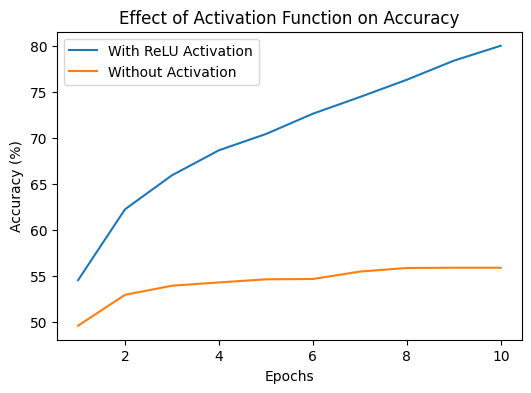

In [14]:
#Task 7.6
import torch.nn as nn
import torch.optim as optim
import torch

# Define the neural network model using ReLU activation
class SimpleNN_ReLU(nn.Module):
    def __init__(self):
        super(SimpleNN_ReLU, self).__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(32 * 32 * 3, 132)
        self.fc2 = nn.Linear(132, 132)
        self.fc3 = nn.Linear(132, 132)
        self.fc4 = nn.Linear(132, 10)
        self.relu = nn.ReLU()  # ReLU activation function

    def forward(self, x):
        x = self.flatten(x)
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.relu(self.fc3(x))
        x = self.fc4(x)  # No activation at the output layer
        return x

# Define the neural network model WITHOUT activation functions
class SimpleNN_NoActivation(nn.Module):
    def __init__(self):
        super(SimpleNN_NoActivation, self).__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(32 * 32 * 3, 132)
        self.fc2 = nn.Linear(132, 132)
        self.fc3 = nn.Linear(132, 132)
        self.fc4 = nn.Linear(132, 10)

    def forward(self, x):
        x = self.flatten(x)
        x = self.fc1(x)  # No activation
        x = self.fc2(x)  # No activation
        x = self.fc3(x)  # No activation
        x = self.fc4(x)  # No activation
        return x

# Training function
def train_model(model, trainloader, criterion, optimizer, epochs=10):
    model.train()
    acc_list = []
    for epoch in range(epochs):
        running_loss = 0.0
        correct = 0
        total = 0

        for inputs, labels in trainloader:
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        acc = 100 * correct / total
        acc_list.append(acc)
        print(f"Epoch {epoch+1}/{epochs}, Loss: {running_loss/len(trainloader):.4f}, Accuracy: {acc:.2f}%")

    return acc_list

# Initialize models
model_relu = SimpleNN_ReLU()
model_no_activation = SimpleNN_NoActivation()

# Define loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer_relu = optim.Adam(model_relu.parameters(), lr=0.001)
optimizer_no_activation = optim.Adam(model_no_activation.parameters(), lr=0.001)

# Train both models
acc_relu = train_model(model_relu, trainloader, criterion, optimizer_relu)
acc_no_activation = train_model(model_no_activation, trainloader, criterion, optimizer_no_activation)

# Plot Accuracy Comparison
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))
plt.plot(range(1, 11), acc_relu, label="With ReLU Activation")
plt.plot(range(1, 11), acc_no_activation, label="Without Activation")
plt.xlabel("Epochs")
plt.ylabel("Accuracy (%)")
plt.title("Effect of Activation Function on Accuracy")
plt.legend()
plt.show()



Epoch 1/10, Loss: 2.3027, Accuracy: 9.81%
Epoch 2/10, Loss: 2.3027, Accuracy: 9.71%
Epoch 3/10, Loss: 2.3027, Accuracy: 9.73%
Epoch 4/10, Loss: 2.3027, Accuracy: 9.66%
Epoch 5/10, Loss: 2.3027, Accuracy: 9.81%
Epoch 6/10, Loss: 2.3027, Accuracy: 9.82%
Epoch 7/10, Loss: 2.3027, Accuracy: 10.01%
Epoch 8/10, Loss: 2.3027, Accuracy: 9.75%
Epoch 9/10, Loss: 2.3027, Accuracy: 9.74%
Epoch 10/10, Loss: 2.3027, Accuracy: 9.81%
Epoch 1/10, Loss: 32.3821, Accuracy: 12.24%
Epoch 2/10, Loss: 2.3935, Accuracy: 12.76%
Epoch 3/10, Loss: 2.2882, Accuracy: 13.53%
Epoch 4/10, Loss: 2.2659, Accuracy: 14.01%
Epoch 5/10, Loss: 2.2559, Accuracy: 14.66%
Epoch 6/10, Loss: 2.2413, Accuracy: 15.36%
Epoch 7/10, Loss: 2.1939, Accuracy: 16.47%
Epoch 8/10, Loss: 2.1300, Accuracy: 17.69%
Epoch 9/10, Loss: 2.1043, Accuracy: 17.64%
Epoch 10/10, Loss: 2.0530, Accuracy: 18.71%


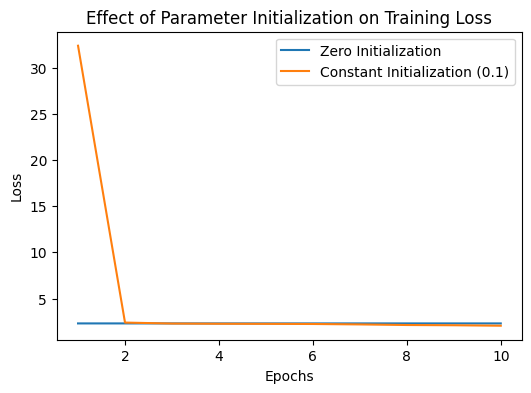

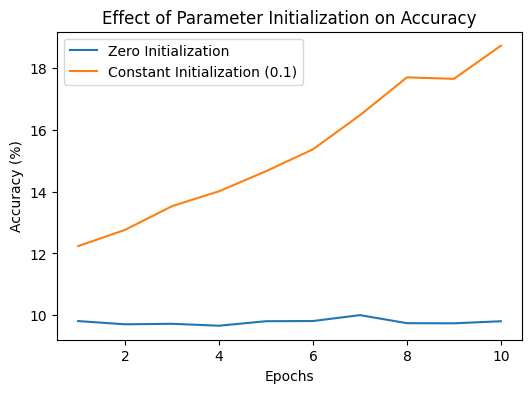

In [22]:
#Task 7.7

import torch.nn as nn
import torch.optim as optim
import torch
import matplotlib.pyplot as plt

# Define a function to initialize weights
def initialize_weights_zero(model):
    for layer in model.children():
        if isinstance(layer, nn.Linear):
            nn.init.zeros_(layer.weight)
            if layer.bias is not None:
                nn.init.zeros_(layer.bias)

def initialize_weights_constant(model, value=0.1):
    for layer in model.children():
        if isinstance(layer, nn.Linear):
            nn.init.constant_(layer.weight, value)
            if layer.bias is not None:
                nn.init.constant_(layer.bias, value)

# Define the modified neural network model
class SimpleNN(nn.Module):
    def __init__(self):
        super(SimpleNN, self).__init__()

        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(32 * 32 * 3, 132)
        self.fc2 = nn.Linear(132, 132)
        self.fc3 = nn.Linear(132, 132)
        self.fc4 = nn.Linear(132, 10)

        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.flatten(x)
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.relu(self.fc3(x))
        x = self.fc4(x)
        return x

# Function to train the model and collect loss & accuracy data
def train_model(model, trainloader, epochs=10):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    loss_values = []
    acc_values = []

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0

        for inputs, labels in trainloader:
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()

            # Compute accuracy
            _, predicted = torch.max(outputs, 1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)

        avg_loss = running_loss / len(trainloader)
        accuracy = 100 * correct / total

        loss_values.append(avg_loss)
        acc_values.append(accuracy)

        print(f"Epoch {epoch+1}/{epochs}, Loss: {avg_loss:.4f}, Accuracy: {accuracy:.2f}%")

    return loss_values, acc_values

# Train with zero initialization
model_zero_init = SimpleNN()
initialize_weights_zero(model_zero_init)
loss_zero_init, acc_zero_init = train_model(model_zero_init, trainloader)

# Train with constant initialization
model_const_init = SimpleNN()
initialize_weights_constant(model_const_init, value=0.1)
loss_const_init, acc_const_init = train_model(model_const_init, trainloader)

# Plot Loss Comparison
plt.figure(figsize=(6, 4))
plt.plot(range(1, 11), loss_zero_init, label="Zero Initialization")
plt.plot(range(1, 11), loss_const_init, label="Constant Initialization (0.1)")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Effect of Parameter Initialization on Training Loss")
plt.legend()
plt.show()

# Plot Accuracy Comparison
plt.figure(figsize=(6, 4))
plt.plot(range(1, 11), acc_zero_init, label="Zero Initialization")
plt.plot(range(1, 11), acc_const_init, label="Constant Initialization (0.1)")
plt.xlabel("Epochs")
plt.ylabel("Accuracy (%)")
plt.title("Effect of Parameter Initialization on Accuracy")
plt.legend()
plt.show()


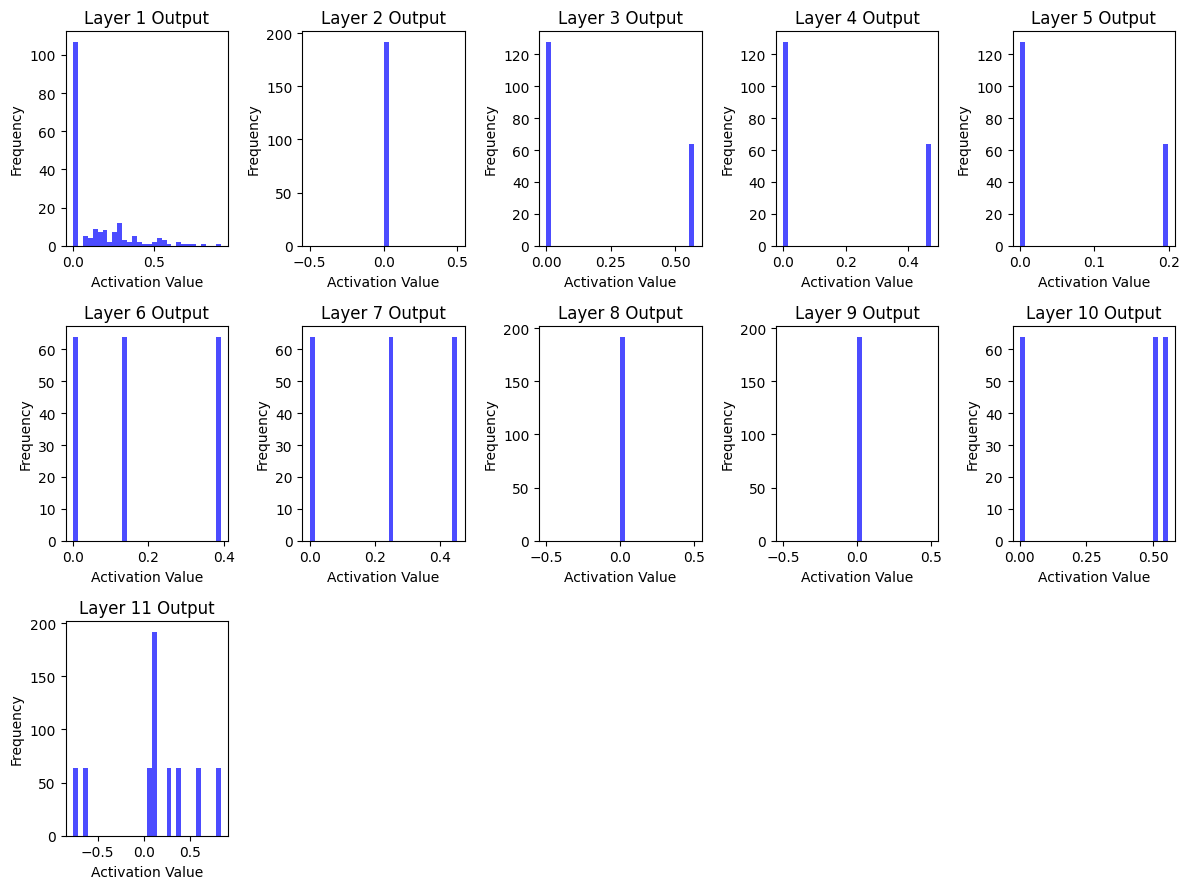

In [24]:
#Task 7.8

import torch.nn as nn
import torch.optim as optim
import torch
import matplotlib.pyplot as plt
import numpy as np

# Define a flexible deep neural network with 10 layers and customizable hidden size
class DeepNN(nn.Module):
    def __init__(self, input_size=32 * 32 * 3, hidden_size=3, output_size=10, num_layers=10):
        super(DeepNN, self).__init__()

        self.flatten = nn.Flatten()
        self.layers = nn.ModuleList()

        # Input layer
        self.layers.append(nn.Linear(input_size, hidden_size))

        # Hidden layers
        for _ in range(num_layers - 1):
            self.layers.append(nn.Linear(hidden_size, hidden_size))

        # Output layer
        self.output_layer = nn.Linear(hidden_size, output_size)

        self.activation = nn.ReLU()  # Using ReLU activation function

    def forward(self, x):
        x = self.flatten(x)
        activations = []

        for layer in self.layers:
            x = self.activation(layer(x))
            activations.append(x.detach().cpu().numpy())  # Store activations for visualization

        x = self.output_layer(x)
        activations.append(x.detach().cpu().numpy())  # Include output layer activations
        return x, activations

# Function to train the model and capture layer activations
def train_and_visualize(model, trainloader, num_epochs=1):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    model.train()

    for epoch in range(num_epochs):
        for inputs, labels in trainloader:
            optimizer.zero_grad()
            outputs, activations = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            break  # Process only one batch for visualization

    return activations  # Return activations from one batch

# Initialize and train the model
model = DeepNN(hidden_size=3)  # You can change the hidden size if needed
activations = train_and_visualize(model, trainloader)

# Dynamically determine the number of rows for subplots
num_layers = len(activations)
rows = (num_layers // 5) + (1 if num_layers % 5 != 0 else 0)

# Visualize the outputs of each layer
plt.figure(figsize=(12, rows * 3))

for i, activation in enumerate(activations):
    plt.subplot(rows, 5, i + 1)
    plt.hist(activation.flatten(), bins=30, alpha=0.7, color='blue')
    plt.title(f"Layer {i+1} Output")
    plt.xlabel("Activation Value")
    plt.ylabel("Frequency")

plt.tight_layout()
plt.show()


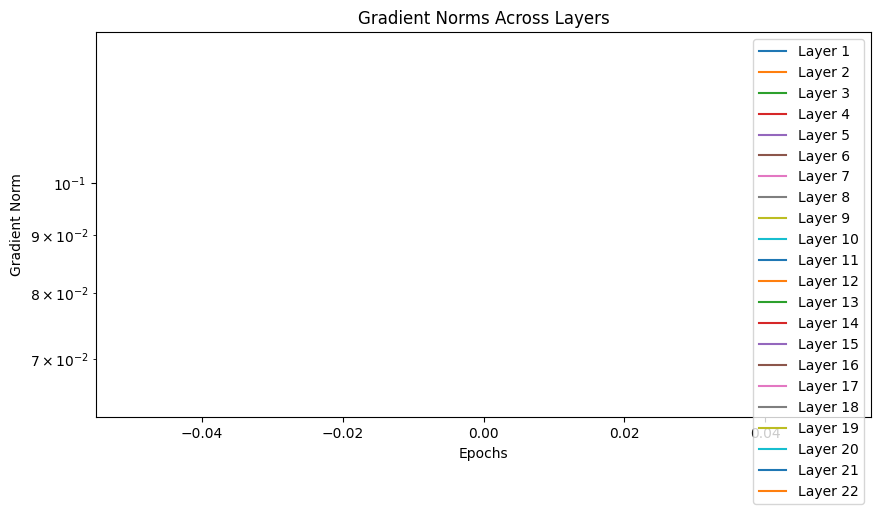

In [32]:
#Task 7.9

import torch.nn as nn
import torch.optim as optim
import torch
import matplotlib.pyplot as plt

# Define a deep neural network with 10 layers
class DeepNN(nn.Module):
    def __init__(self, input_size=32 * 32 * 3, hidden_size=3, output_size=10, num_layers=10):
        super(DeepNN, self).__init__()

        self.flatten = nn.Flatten()
        self.layers = nn.ModuleList()

        # Input layer
        self.layers.append(nn.Linear(input_size, hidden_size))

        # Hidden layers
        for _ in range(num_layers - 1):
            self.layers.append(nn.Linear(hidden_size, hidden_size))

        # Output layer
        self.output_layer = nn.Linear(hidden_size, output_size)

        self.activation = nn.ReLU()  # Using ReLU activation function

    def forward(self, x):
        x = self.flatten(x)
        for layer in self.layers:
            x = self.activation(layer(x))
        x = self.output_layer(x)
        return x

# Function to train the model and track gradient norms
def train_and_track_gradients(model, trainloader, num_epochs=1):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    model.train()
    gradient_norms = []

    for epoch in range(num_epochs):
        for inputs, labels in trainloader:
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()

            # Collect gradient norms for each layer
            layer_gradients = []
            for param in model.parameters():
                if param.grad is not None:
                    layer_gradients.append(param.grad.norm().item())

            gradient_norms.append(layer_gradients)  # Store per-epoch gradient norms
            optimizer.step()
            break  # Process only one batch for gradient analysis

    return gradient_norms

# Initialize and train the model
model = DeepNN(hidden_size=3)  # You can change the hidden size if needed
gradient_norms = train_and_track_gradients(model, trainloader)

# Convert gradient norms to a format suitable for plotting
gradient_norms = torch.tensor(gradient_norms).T  # Transpose to get layers on the Y-axis

# Plot gradient norms for each layer
plt.figure(figsize=(10, 5))

for i, layer_norms in enumerate(gradient_norms):
    plt.plot(range(len(layer_norms)), layer_norms, label=f"Layer {i+1}")

plt.xlabel("Epochs")
plt.ylabel("Gradient Norm")
plt.yscale("log")  # Use logarithmic scale for better visibility
plt.title("Gradient Norms Across Layers")
plt.legend()
plt.show()
